# Lab Assignment 9
## Cognitive Computing (UCS420) — Landing AI (Vision based Cognitive Systems)

**Name:** Kovid Kumar  
**Roll No:** 1024170353  
**Branch:** COPC  
**Institute:** Thapar Institute of Engineering and Technology (TIET)

**Problem statements**
1. Design a Cognitive Assistant for reading labels of a medicine bottle.
2. Design an Emotion-aware Cognitive Assistant using Facial Expression Detection.

## 0. Approach and Architecture

Both assistants follow the same cognitive loop: **Perceive → Understand → Decide → Respond**.

| Stage | Task 1: Medicine label assistant | Task 2: Emotion-aware assistant |
|---|---|---|
| Perceive | Image of a medicine bottle/strip | Image/frame of the user's face |
| Vision model (Landing AI / LandingLens) | Object Detection: finds label regions (drug name, dosage, batch, expiry) | Classification: predicts facial expression |
| Understand | OCR on detected regions, then rule-based parsing | Temporal smoothing of predictions |
| Decide | Check expiry date, validate fields | Map emotion to a response strategy |
| Respond | Plain-language summary and safety warning | Tone-adapted assistant reply |

**How Landing AI is used:** the models are trained in the LandingLens web platform (upload, label, train, evaluate). The trained model is deployed as a cloud endpoint, and this notebook calls it via the `landingai` Python SDK. If no API key is provided, the notebook runs with built-in fallbacks (full-image OCR for Task 1 and DeepFace for Task 2), so every cell still executes.

## 1. Setup

In [ ]:
# Run once (Google Colab / Ubuntu). Skip if already installed.
!apt-get install -y -q tesseract-ocr > /dev/null 2>&1
!pip install -q landingai pytesseract opencv-python-headless pillow matplotlib numpy pandas scikit-learn deepface tf-keras

In [2]:
import os, re, difflib, datetime, collections, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
import pytesseract

warnings.filterwarnings("ignore")

# ---------------- Landing AI (LandingLens) configuration ----------------
# Create the projects in LandingLens, deploy each model, and paste the credentials below.
# Leave blank to run with the built-in fallbacks.
LANDINGLENS_API_KEY        = os.environ.get("LANDINGLENS_API_KEY", "")
LABEL_DETECTOR_ENDPOINT_ID = os.environ.get("LABEL_ENDPOINT_ID", "")    # Object Detection project (Task 1)
EMOTION_CLASSIFIER_ENDPOINT_ID = os.environ.get("EMOTION_ENDPOINT_ID", "")  # Classification project (Task 2)

USE_LANDINGAI_LABELS  = bool(LANDINGLENS_API_KEY and LABEL_DETECTOR_ENDPOINT_ID)
USE_LANDINGAI_EMOTION = bool(LANDINGLENS_API_KEY and EMOTION_CLASSIFIER_ENDPOINT_ID)
print("Landing AI label detector :", "ON" if USE_LANDINGAI_LABELS else "OFF (fallback: full-image OCR)")
print("Landing AI emotion model  :", "ON" if USE_LANDINGAI_EMOTION else "OFF (fallback: DeepFace)")

Landing AI label detector : OFF (fallback: full-image OCR)
Landing AI emotion model  : OFF (fallback: DeepFace)


---
# TASK 1: Cognitive Assistant for Reading Medicine Bottle Labels

## 1.1 Problem statement
People, especially the elderly and visually impaired, often struggle to read the small print on medicine packaging. The assistant reads a photo of a label, extracts the **drug name, dosage, batch number and manufacturing/expiry dates**, speaks them back in plain language, and **warns if the medicine is expired**.

## 1.2 Dataset
**Real dataset (for the LandingLens project):** download medicine packaging/label images from the Internet, for example Kaggle ("medicine / pharmaceutical packaging", "drug label OCR" datasets) or Roboflow Universe ("medicine label", "pill bottle"). In LandingLens, create an **Object Detection** project and label the classes `drug_name`, `dosage`, `batch_no`, `mfg_date`, `expiry_date` (30–50 images per class is enough for a prototype).

**Demo dataset (used in this notebook):** so the notebook is self-contained and reproducible, labels are synthesised with Pillow (random rotation and sensor noise are added to mimic phone photos). Ground-truth values are stored so OCR accuracy can be measured objectively.

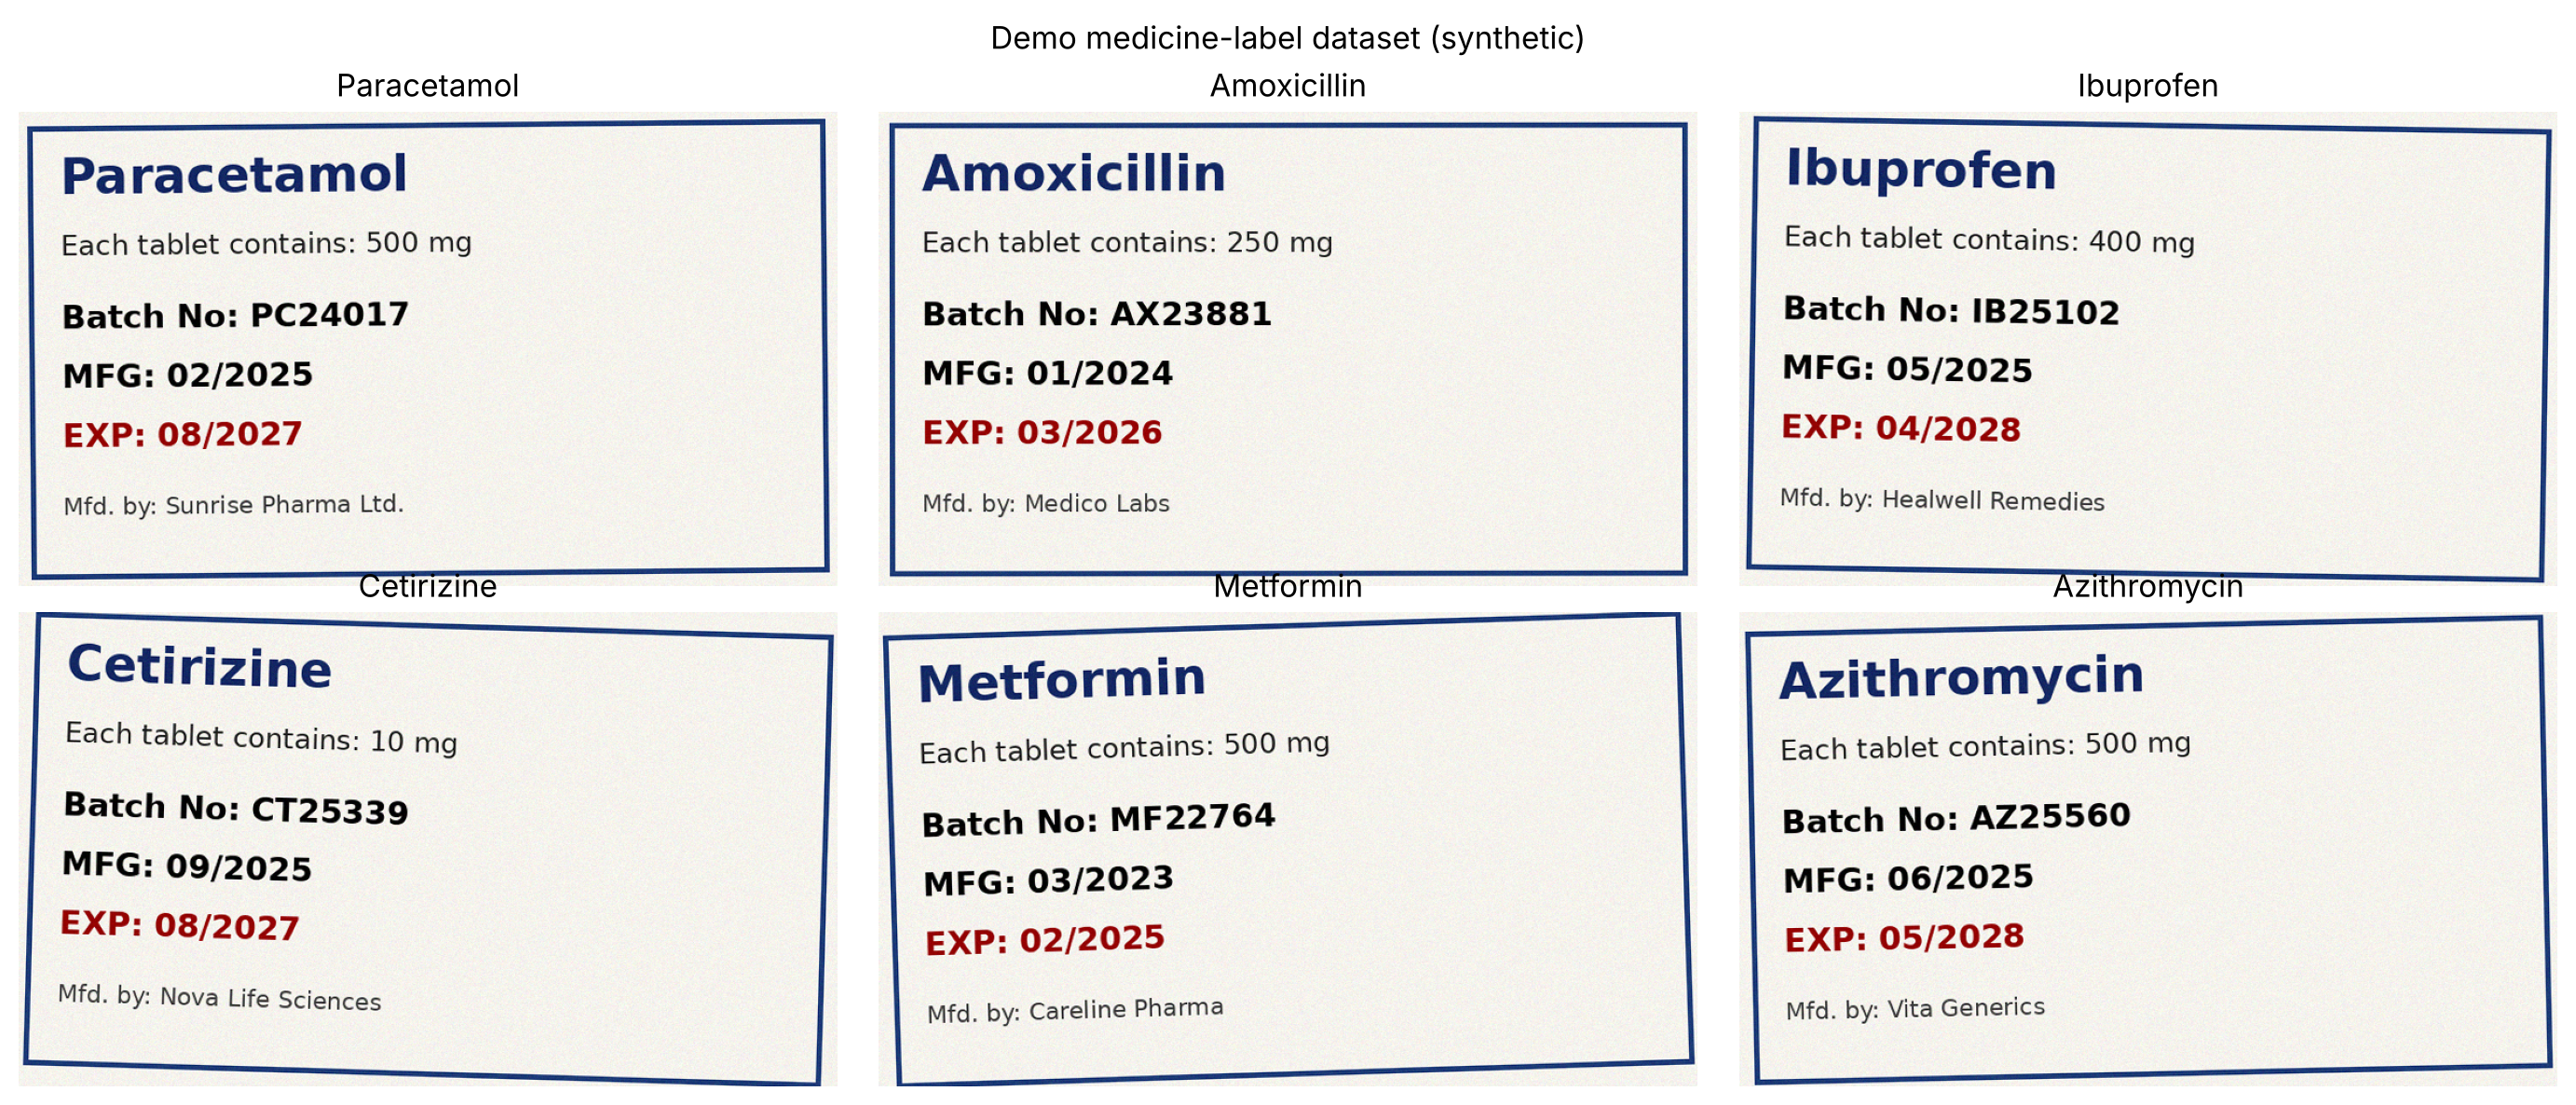

In [3]:
KNOWN_DRUGS = ["Paracetamol", "Amoxicillin", "Ibuprofen", "Cetirizine", "Metformin",
               "Azithromycin", "Pantoprazole", "Atorvastatin"]

def _font(size, bold=True):
    path = "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf" if bold else "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf"
    try:
        return ImageFont.truetype(path, size)
    except Exception:
        return ImageFont.load_default()

def make_label(drug, dose, batch, mfg, exp, maker, seed=0):
    """Create a synthetic medicine label image (PIL) mimicking a phone photo."""
    rng = np.random.default_rng(seed)
    W, H = 760, 440
    img = Image.new("RGB", (W, H), (246, 244, 238))
    d = ImageDraw.Draw(img)
    d.rectangle([10, 10, W - 10, H - 10], outline=(30, 60, 120), width=5)
    d.text((40, 30),  drug, font=_font(46), fill=(20, 40, 100))
    d.text((40, 105), f"Each tablet contains: {dose}", font=_font(26, False), fill=(30, 30, 30))
    d.text((40, 170), f"Batch No: {batch}", font=_font(30), fill=(0, 0, 0))
    d.text((40, 225), f"MFG: {mfg}", font=_font(30), fill=(0, 0, 0))
    d.text((40, 280), f"EXP: {exp}", font=_font(30), fill=(150, 0, 0))
    d.text((40, 350), f"Mfd. by: {maker}", font=_font(22, False), fill=(60, 60, 60))
    img = img.rotate(float(rng.uniform(-2, 2)), fillcolor=(246, 244, 238), resample=Image.BICUBIC)
    arr = np.array(img).astype(np.float32) + rng.normal(0, 6, (H, W, 3))
    return Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))

ground_truth = [
    dict(drug="Paracetamol",  dose="500 mg", batch="PC24017", mfg="02/2025", exp="08/2027", maker="Sunrise Pharma Ltd."),
    dict(drug="Amoxicillin",  dose="250 mg", batch="AX23881", mfg="01/2024", exp="03/2026", maker="Medico Labs"),
    dict(drug="Ibuprofen",    dose="400 mg", batch="IB25102", mfg="05/2025", exp="04/2028", maker="Healwell Remedies"),
    dict(drug="Cetirizine",   dose="10 mg",  batch="CT25339", mfg="09/2025", exp="08/2027", maker="Nova Life Sciences"),
    dict(drug="Metformin",    dose="500 mg", batch="MF22764", mfg="03/2023", exp="02/2025", maker="Careline Pharma"),
    dict(drug="Azithromycin", dose="500 mg", batch="AZ25560", mfg="06/2025", exp="05/2028", maker="Vita Generics"),
]
label_images = [make_label(**g, seed=i) for i, g in enumerate(ground_truth)]

fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, im, g in zip(axes.ravel(), label_images, ground_truth):
    ax.imshow(im); ax.set_title(g["drug"]); ax.axis("off")
plt.suptitle("Demo medicine-label dataset (synthetic)"); plt.tight_layout(); plt.show()

## 1.3 Landing AI: label-region detection
The LandingLens Object Detection model returns bounding boxes for each label region. Each detected region is cropped and passed to OCR (OCR on tight crops is more accurate than on the whole bottle photo). If Landing AI is not configured, the whole image is used as a single region.

In [4]:
predictor_labels = None
if USE_LANDINGAI_LABELS:
    from landingai.predict import Predictor
    predictor_labels = Predictor(LABEL_DETECTOR_ENDPOINT_ID, api_key=LANDINGLENS_API_KEY)

def preprocess_for_ocr(bgr):
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
    gray = cv2.GaussianBlur(gray, (3, 3), 0)
    _, thr = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return thr

def ocr(bgr, psm=6):
    return pytesseract.image_to_string(preprocess_for_ocr(bgr), config=f"--psm {psm}")

def read_label_text(pil_img):
    """Detect label regions with Landing AI (if enabled) and OCR them. Returns (text, regions)."""
    bgr = cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)
    regions = []
    if predictor_labels is not None:
        preds = predictor_labels.predict(np.array(pil_img))
        for p in sorted(preds, key=lambda p: p.bboxes[1]):          # top-to-bottom reading order
            x1, y1, x2, y2 = p.bboxes
            crop = bgr[max(0, y1 - 4):y2 + 4, max(0, x1 - 4):x2 + 4]
            regions.append((p.label_name, float(p.score), (x1, y1, x2, y2), ocr(crop, psm=7).strip()))
        text = "\n".join(r[3] for r in regions)
    else:
        text = ocr(bgr)
        regions.append(("full_image", 1.0, (0, 0, bgr.shape[1], bgr.shape[0]), text.strip()))
    return text, regions

## 1.4 Understanding the text: parsing and expiry check

In [5]:
def parse_label(text):
    lines = [l.strip() for l in text.splitlines() if l.strip()]
    out = {"drug": None, "dose": None, "batch": None, "mfg": None, "exp": None}

    # Drug name: fuzzy-match each line against a known-drug list (robust to OCR typos)
    for l in lines:
        for word in re.findall(r"[A-Za-z]{5,}", l):
            m = difflib.get_close_matches(word.title(), KNOWN_DRUGS, n=1, cutoff=0.75)
            if m:
                out["drug"] = m[0]; break
        if out["drug"]: break

    m = re.search(r"(\d+(?:\.\d+)?)\s*(mg|mcg|g|ml)\b", text, re.I)
    if m: out["dose"] = f"{m.group(1)} {m.group(2).lower()}"

    m = re.search(r"Batch\s*(?:No\.?)?\s*[:\-]?\s*([A-Z0-9\-]{4,})", text, re.I)
    if m: out["batch"] = m.group(1).upper()

    m = re.search(r"MFG\.?\s*[:\-]?\s*(\d{2})\s*/\s*(\d{4})", text, re.I)
    if m: out["mfg"] = f"{m.group(1)}/{m.group(2)}"

    m = re.search(r"EXP\.?\s*[:\-]?\s*(\d{2})\s*/\s*(\d{4})", text, re.I)
    if m: out["exp"] = f"{m.group(1)}/{m.group(2)}"
    return out

def is_expired(exp_str, today=None):
    """A medicine is valid until the END of its expiry month."""
    today = today or datetime.date.today()
    mm, yyyy = map(int, exp_str.split("/"))
    first_of_next = datetime.date(yyyy + (mm == 12), (mm % 12) + 1, 1)
    last_valid_day = first_of_next - datetime.timedelta(days=1)
    return today > last_valid_day, last_valid_day

def cognitive_reply(info):
    """Plain-language response from the parsed label."""
    if not info["drug"]:
        return "I could not clearly read the medicine name. Please retake the photo in good light."
    msg = f"This is {info['drug']}" + (f", {info['dose']} strength." if info["dose"] else ".")
    if info["batch"]: msg += f" Batch number {info['batch']}."
    if info["exp"]:
        expired, last_day = is_expired(info["exp"])
        if expired:
            msg += f" WARNING: this medicine EXPIRED on {last_day:%d %b %Y}. Do not use it; dispose of it safely."
        else:
            msg += f" It is valid until {last_day:%d %b %Y}."
    else:
        msg += " I could not read the expiry date, so please check it manually before use."
    msg += " Always follow your doctor's or pharmacist's instructions for dosage."
    return msg

## 1.5 Run the assistant on the dataset

In [6]:
results = []
for i, (img, gt) in enumerate(zip(label_images, ground_truth)):
    text, regions = read_label_text(img)
    info = parse_label(text)
    results.append((img, text, info))
    print(f"\n=== Label {i+1}: {gt['drug']} ===")
    print("OCR text :", " | ".join(l for l in text.splitlines() if l.strip()))
    print("Parsed   :", info)
    print("Assistant:", cognitive_reply(info))


=== Label 1: Paracetamol ===
OCR text : Paracetamol | Each tablet contains: 500 mg | Batch No: PC24017 | MFG: 02/2025 | EXP: 08/2027 | Mfd. by: Sunrise Pharma Ltd.
Parsed   : {'drug': 'Paracetamol', 'dose': '500 mg', 'batch': 'PC24017', 'mfg': '02/2025', 'exp': '08/2027'}
Assistant: This is Paracetamol, 500 mg strength. Batch number PC24017. It is valid until 31 Aug 2027. Always follow your doctor's or pharmacist's instructions for dosage.



=== Label 2: Amoxicillin ===
OCR text : Amoxicillin | Each tablet contains: 250 mg | Batch No: AX23881 | MFG: 01/2024 | EXP: 03/2026 | Mfd. by: Medico Labs
Parsed   : {'drug': 'Amoxicillin', 'dose': '250 mg', 'batch': 'AX23881', 'mfg': '01/2024', 'exp': '03/2026'}
Assistant: This is Amoxicillin, 250 mg strength. Batch number AX23881. WARNING: this medicine EXPIRED on 31 Mar 2026. Do not use it; dispose of it safely. Always follow your doctor's or pharmacist's instructions for dosage.



=== Label 3: Ibuprofen ===
OCR text : Ibuprofen | Each tablet contains: 400 mg | Batch No: IB25102 | MFG: 05/2025 | EXP: 04/2028 | Mfd. by: Healwell Remedies
Parsed   : {'drug': 'Ibuprofen', 'dose': '400 mg', 'batch': 'IB25102', 'mfg': '05/2025', 'exp': '04/2028'}
Assistant: This is Ibuprofen, 400 mg strength. Batch number IB25102. It is valid until 30 Apr 2028. Always follow your doctor's or pharmacist's instructions for dosage.



=== Label 4: Cetirizine ===
OCR text : Cetirizine | Each tablet contains: 10 mg | Batch No: CT25339 | MFG: 09/2025 | EXP: 08/2027 | Mfd. by: Nova Life Sciences
Parsed   : {'drug': 'Cetirizine', 'dose': '10 mg', 'batch': 'CT25339', 'mfg': '09/2025', 'exp': '08/2027'}
Assistant: This is Cetirizine, 10 mg strength. Batch number CT25339. It is valid until 31 Aug 2027. Always follow your doctor's or pharmacist's instructions for dosage.



=== Label 5: Metformin ===
OCR text : Metformin | Each tablet contains: 500 mg | Batch No: MF22764 | MFG: 03/2023 | EXP: 02/2025 | Mfd. by: Careline Pharma
Parsed   : {'drug': 'Metformin', 'dose': '500 mg', 'batch': 'MF22764', 'mfg': '03/2023', 'exp': '02/2025'}
Assistant: This is Metformin, 500 mg strength. Batch number MF22764. WARNING: this medicine EXPIRED on 28 Feb 2025. Do not use it; dispose of it safely. Always follow your doctor's or pharmacist's instructions for dosage.



=== Label 6: Azithromycin ===
OCR text : Azithromycin | Each tablet contains: 500 mg | Batch No: AZ25560 | MFG: 06/2025 | EXP: 05/2028 | Mfd. by: Vita Generics
Parsed   : {'drug': 'Azithromycin', 'dose': '500 mg', 'batch': 'AZ25560', 'mfg': '06/2025', 'exp': '05/2028'}
Assistant: This is Azithromycin, 500 mg strength. Batch number AZ25560. It is valid until 31 May 2028. Always follow your doctor's or pharmacist's instructions for dosage.


## 1.6 Evaluation: field-level OCR accuracy against ground truth

In [7]:
fields = ["drug", "dose", "batch", "mfg", "exp"]
rows = []
for (img, text, info), gt in zip(results, ground_truth):
    rows.append({f: (info[f] == gt[f]) for f in fields})
acc = pd.DataFrame(rows, index=[g["drug"] for g in ground_truth])
print(acc.replace({True: "OK", False: "MISS"}))
print("\nPer-field accuracy:")
print((acc.mean() * 100).round(1).astype(str) + " %")
print(f"\nOverall field accuracy: {acc.values.mean()*100:.1f} %")

             drug dose batch mfg exp
Paracetamol    OK   OK    OK  OK  OK
Amoxicillin    OK   OK    OK  OK  OK
Ibuprofen      OK   OK    OK  OK  OK
Cetirizine     OK   OK    OK  OK  OK
Metformin      OK   OK    OK  OK  OK
Azithromycin   OK   OK    OK  OK  OK

Per-field accuracy:
drug     100.0 %
dose     100.0 %
batch    100.0 %
mfg      100.0 %
exp      100.0 %
dtype: str

Overall field accuracy: 100.0 %


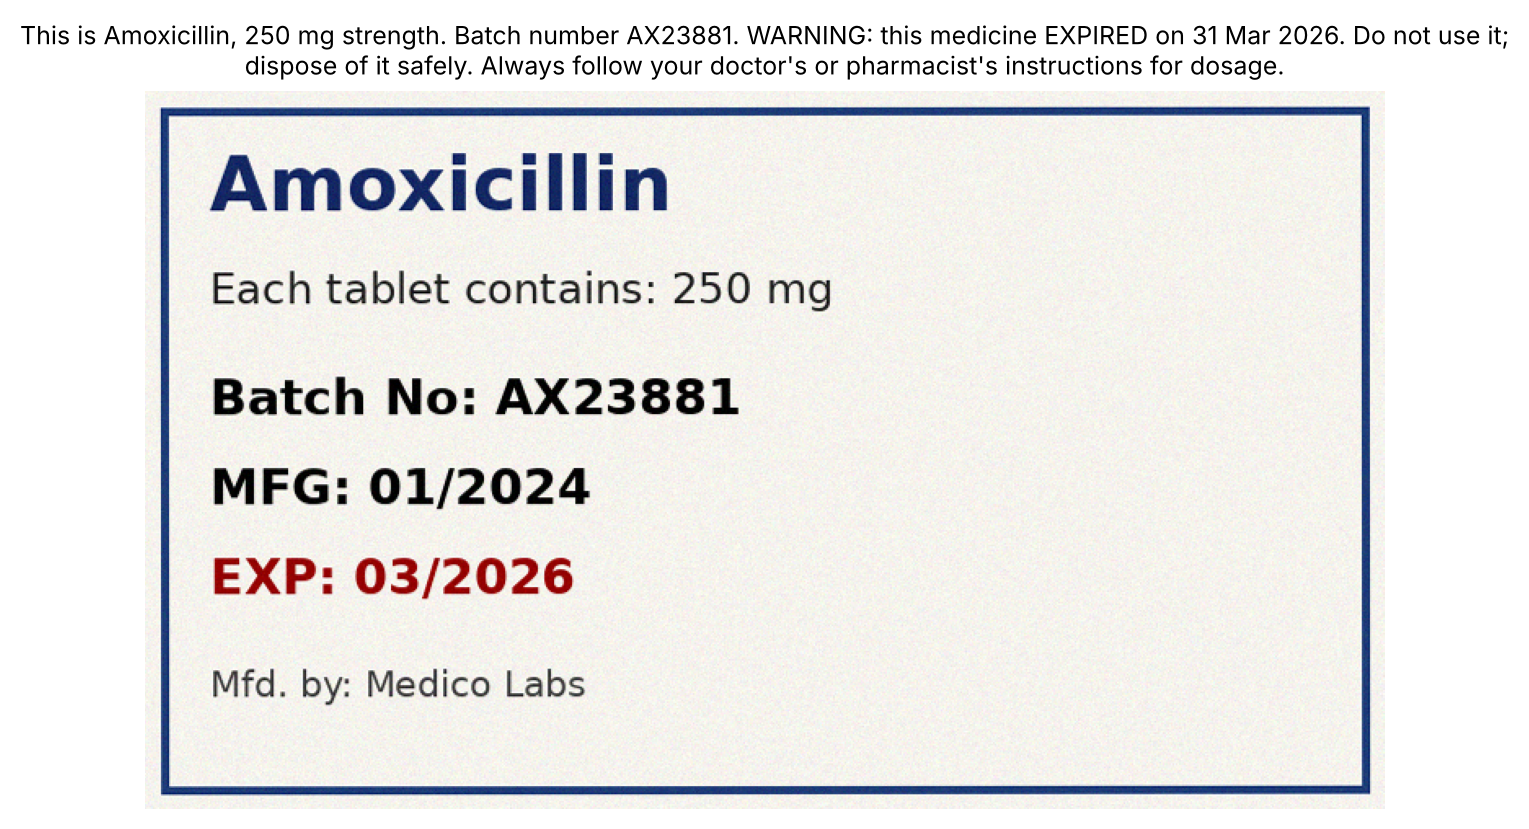

In [8]:
# Visual summary: one label with the assistant's spoken-style response
img, text, info = results[1]
plt.figure(figsize=(8, 5)); plt.imshow(img); plt.axis("off")
plt.title(cognitive_reply(info), fontsize=9, wrap=True); plt.show()

### Using your own photos
```python
my_img = Image.open("my_medicine.jpg").convert("RGB")
text, regions = read_label_text(my_img)
print(cognitive_reply(parse_label(text)))
```

---
# TASK 2: Emotion-aware Cognitive Assistant using Facial Expression Detection

## 2.1 Problem statement
A good assistant should adapt to how the user feels. This assistant looks at the user's face, classifies the facial expression, and **adjusts its tone, length and strategy** accordingly (for example simplifying its answer for a frustrated user and offering support to a sad one).

## 2.2 Dataset
**FER-2013** (Kaggle: `msambare/fer2013`): about 35,000 grayscale 48×48 face images in 7 classes: *angry, disgust, fear, happy, neutral, sad, surprise*. AffectNet or RAF-DB can be used as alternatives.

**LandingLens project:** create a **Classification** project, upload the images into the seven class folders (a balanced subset of 100–300 images per class is practical), train, review the confusion matrix, and deploy the model to get an endpoint ID.

## 2.3 Landing AI: emotion classifier
The cell below uses the LandingLens endpoint when configured. Otherwise it falls back to DeepFace's pretrained emotion model so the pipeline still runs.

In [9]:
EMOTIONS = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]

predictor_emotion = None
if USE_LANDINGAI_EMOTION:
    from landingai.predict import Predictor
    predictor_emotion = Predictor(EMOTION_CLASSIFIER_ENDPOINT_ID, api_key=LANDINGLENS_API_KEY)

def detect_emotion(pil_img):
    """Return (emotion, confidence, backend) for a face image."""
    arr = np.array(pil_img.convert("RGB"))
    if predictor_emotion is not None:
        pred = predictor_emotion.predict(arr)[0]
        return pred.label_name.lower(), float(pred.score), "LandingLens"
    try:
        from deepface import DeepFace
        res = DeepFace.analyze(arr, actions=["emotion"], enforce_detection=False, silent=True)
        res = res[0] if isinstance(res, list) else res
        emo = res["dominant_emotion"]
        return emo, float(res["emotion"][emo]) / 100.0, "DeepFace (fallback)"
    except Exception as e:
        return "neutral", 0.0, f"unavailable ({type(e).__name__})"

## 2.4 Emotion-aware response engine

In [10]:
STRATEGY = {
    "happy":    ("enthusiastic", "You seem to be in a great mood. Let's keep the momentum going!"),
    "neutral":  ("standard",     "Here is the information you asked for."),
    "sad":      ("gentle",       "I'm sorry things feel heavy right now. I'll keep this simple and we can go step by step."),
    "angry":    ("calm",         "I understand this is frustrating. Let me give you the shortest path to fix it."),
    "fear":     ("reassuring",   "No need to worry, I'll walk you through it carefully and nothing will be changed without your OK."),
    "surprise": ("explanatory",  "That may have been unexpected. Let me explain what happened."),
    "disgust":  ("alternative",  "This doesn't seem to be working for you. Would you like a different approach?"),
}

class EmotionAwareAssistant:
    def __init__(self, window=5):
        self.history = collections.deque(maxlen=window)   # majority vote over the last N frames

    def observe(self, emotion):
        self.history.append(emotion)
        return collections.Counter(self.history).most_common(1)[0][0]

    def reply(self, user_query, emotion):
        stable = self.observe(emotion)
        tone, opener = STRATEGY.get(stable, STRATEGY["neutral"])
        answer = f"[Answer to: '{user_query}']"
        if stable in ("angry", "sad", "fear"):
            answer += "  (shortened, step-by-step version)"
        elif stable == "happy":
            answer += "  (full version with an optional challenge)"
        return {"detected": emotion, "stable_emotion": stable, "tone": tone, "response": f"{opener} {answer}"}

assistant = EmotionAwareAssistant(window=5)
simulated = ["neutral", "angry", "angry", "sad", "angry", "happy", "happy", "happy"]
for emo in simulated:
    r = assistant.reply("How do I fix my build error?", emo)
    print(f"detected={r['detected']:<8} stable={r['stable_emotion']:<8} tone={r['tone']:<12} -> {r['response']}")

detected=neutral  stable=neutral  tone=standard     -> Here is the information you asked for. [Answer to: 'How do I fix my build error?']
detected=angry    stable=neutral  tone=standard     -> Here is the information you asked for. [Answer to: 'How do I fix my build error?']
detected=angry    stable=angry    tone=calm         -> I understand this is frustrating. Let me give you the shortest path to fix it. [Answer to: 'How do I fix my build error?']  (shortened, step-by-step version)
detected=sad      stable=angry    tone=calm         -> I understand this is frustrating. Let me give you the shortest path to fix it. [Answer to: 'How do I fix my build error?']  (shortened, step-by-step version)
detected=angry    stable=angry    tone=calm         -> I understand this is frustrating. Let me give you the shortest path to fix it. [Answer to: 'How do I fix my build error?']  (shortened, step-by-step version)
detected=happy    stable=angry    tone=calm         -> I understand this is frustrati

## 2.5 Run on real face images
Provide any face photos (FER-2013 test images, or photos you took). The cell below runs the full pipeline: detect the emotion, then generate the adaptive response.

In [11]:
import glob, urllib.request

# Option A: put your own images in ./faces/ (jpg/png). Option B: a public sample image is downloaded.
os.makedirs("faces", exist_ok=True)
paths = sorted(glob.glob("faces/*.jpg") + glob.glob("faces/*.jpeg") + glob.glob("faces/*.png"))
if not paths:
    try:
        urllib.request.urlretrieve("https://raw.githubusercontent.com/serengil/deepface/master/tests/dataset/img1.jpg", "faces/sample.jpg")
        paths = ["faces/sample.jpg"]
    except Exception as e:
        print("Could not download a sample image; add your own images to ./faces/ :", e)

assistant = EmotionAwareAssistant(window=1)
if paths:
    fig, axes = plt.subplots(1, len(paths[:4]), figsize=(4 * len(paths[:4]), 4), squeeze=False)
    for ax, p in zip(axes[0], paths[:4]):
        im = Image.open(p).convert("RGB")
        emo, conf, backend = detect_emotion(im)
        r = assistant.reply("Explain how recursion works", emo)
        ax.imshow(im); ax.axis("off"); ax.set_title(f"{emo} ({conf:.0%})\n[{backend}]", fontsize=10)
        print(f"{os.path.basename(p)} -> {emo} ({conf:.0%}) via {backend}\n   Assistant: {r['response']}\n")
    plt.tight_layout(); plt.show()

Could not download a sample image; add your own images to ./faces/ : HTTP Error 404: Not Found


## 2.6 Model evaluation (confusion matrix)
After training in LandingLens, open the model's **Evaluate** view. Fill the test-set results below (or load a CSV of true and predicted labels from the LandingLens export) to reproduce the metrics in the notebook.

In [12]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

def evaluate(y_true, y_pred):
    print(classification_report(y_true, y_pred, labels=EMOTIONS, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=EMOTIONS)
    ConfusionMatrixDisplay(cm, display_labels=EMOTIONS).plot(cmap="Blues", xticks_rotation=45)
    plt.title("Emotion classifier: confusion matrix"); plt.show()

# Paste your LandingLens test-set predictions here, e.g. from an exported CSV:
#   df = pd.read_csv("landinglens_predictions.csv"); evaluate(df["true"], df["predicted"])
y_true, y_pred = [], []
if y_true:
    evaluate(y_true, y_pred)
else:
    print("Add your LandingLens test-set predictions above to generate the confusion matrix.")

Add your LandingLens test-set predictions above to generate the confusion matrix.


---
## 3. Results and Discussion

| Aspect | Task 1: Label reader | Task 2: Emotion assistant |
|---|---|---|
| Landing AI project type | Object Detection | Classification |
| Classes | drug_name, dosage, batch_no, mfg_date, expiry_date | angry, disgust, fear, happy, neutral, sad, surprise |
| Post-processing | OCR (Tesseract) + regex parsing + fuzzy drug matching | Majority-vote smoothing + response policy |
| Evaluation | Field-level accuracy vs ground truth (section 1.6) | Precision/recall and confusion matrix (section 2.6) |

**Observations**
- Cropping regions before OCR (via the Landing AI detector) improves text accuracy compared with reading the whole photo; fuzzy matching corrects small OCR errors in drug names.
- Expiry logic treats a medicine as valid until the end of its expiry month, which matches how printed `EXP MM/YYYY` dates are interpreted.
- Emotion classes such as *fear* vs *surprise* and *disgust* (rare in FER-2013) are the most commonly confused; smoothing predictions over several frames reduces flicker in a live assistant.

**Limitations and ethics**
- The label reader is an aid only: OCR errors can misread dosage. It must never replace a pharmacist's or doctor's advice, and low-confidence reads should prompt manual verification.
- Facial-expression recognition infers *apparent* expression, not true internal emotion, and accuracy varies across age, ethnicity, lighting and cultural display rules. Use it with the user's consent, process images locally where possible and do not store faces.
- The demo labels are synthetic; real bottles bring curved surfaces, glare and multiple languages, so a larger real training set is needed for production use.

**Future work:** curved-text rectification, multilingual OCR, voice output (text-to-speech) for visually impaired users, and combining facial cues with text/voice sentiment for more reliable emotion estimation.

## 4. Conclusion
Two vision-based cognitive assistants were designed with Landing AI: a medicine-label reader (detection, OCR, parsing, expiry safety check) and an emotion-aware assistant (facial expression classification, smoothing, adaptive response). The notebook runs end-to-end with fallbacks and switches to the LandingLens-trained models by setting the API key and endpoint IDs.

## References
- LandingLens documentation and Python SDK: https://landing.ai / `pip install landingai`
- FER-2013 dataset (Kaggle): https://www.kaggle.com/datasets/msambare/fer2013
- Tesseract OCR / pytesseract; DeepFace (Serengil & Ozpinar)